# Replication of Cai et al. (2015): Social Networks and the Decision to Insure <a class ="tocskip">

Project by [Duc Huy Nguyen](https://github.com/hn1802-uw), Autumn 2026

---

This notebook contains my replication of the results from the following paper:
> Cai, J., de Janvry, A., & Sadoulet, E. (2015). Social networks and the decision to insure. American Economic Journal: Applied Economics, 7(2), 81–108.

**Downloading and viewing this notebook:**

* The best way to view this notebook is by downloading it and the repository it is located in from [Github](https://github.com/hn1802-uw/Social-Networks-and-the-Decision-to-Insure)

* The original paper, as well as the data and code provided by the authors can be accessed [here](https://www.aeaweb.org/articles?id=10.1257/app.20130442).

**Replication and extenion**

* For the replication, I try to cover only the main result of the paper so readers can easily follow and compare. 

* Extension

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
from IPython.display import display

from auxiliary.plots import (
    plot_dag, 
    plot_village_design, 
    plot_household_design,
)

from auxiliary.data import (
    VARIABLE_LABELS,
    check_data,
    clean,
    load_analysis_data,
    load_price_data,
    main_sample,
    placebo_sample,
)
from auxiliary.estimation import (
    balance_table,
    eq1_network_model,
    eq2_price_model,
    eq3_knowledge_model,
    eq4_info_iv_model,
    price_balance_table,
    regression_table,
    style_table,
    summary_table,
)

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)

## 1. Introduction and Background

Cai et al. (2015) examine the impact of social network to farmers decision to buy insurance product using data gathered from China. The research team designed a randomized experiment based on the introduction of a new weather insurance policy for rice farmers offered by the People's Insurance Company of China (PICC), China's largest insurance provider. Working jointly with PICC, the experiment involved 5,300 households across 185 villages of rural China. A noteworthy feature of this paper is the design not only allow researchers to identify the causal effects of social networks on product adoption, but also observe the role of various channels through social networks operate.

This paper contributes to the social network literature by using randomized experimental methods to estimate the causal effect of social networks on weather insurance purchase and the monetary equivalence of this effect. From a policy viewpoint, this paper also look into how to improve weather insurance take-up. Even with heavy government subsidies, evidence still shows that adoption rates are row for weather insurance.

**Background:**

The insurance contract is as follow. The actuarially fair price is 12 RMB (= 0.15 USD) per mu (= 0.067 hectare) per season. The goverment gives a 70 percent subsidy on the premium so farmers only pay the remaining 3.6 RMB per mu. The insurance covers natural disasters, including heavy rain, flood, windstorm,
extremely high or low temperatures, and drought. The product is actually a great
deal for farmers, as the postsubsidy price is only around 1 percent of the production
cost.

## 2. Experimental Design and Randomization

The experiment assumes that improving farmer's understading of insurance reinforces take-up. In order to generate variation in product understading, two types of information sestion were introduced:
* Simple session that took around 20 minutes
* Intensive sessions that took around 45 minutes that cover the simple session plus an explaination of how insurance works and expected benefits.

In each village, 2 rounds of villages were offered to introduce the insurance product in both simple and intensive sessions simultanously. To allow time for information sharing, second round are held three days after first round. The effect would be realized by lookking whether second round participants are more likely to by insurance if they have more friends that were invited to first round intensive sessions. 

### Randomization

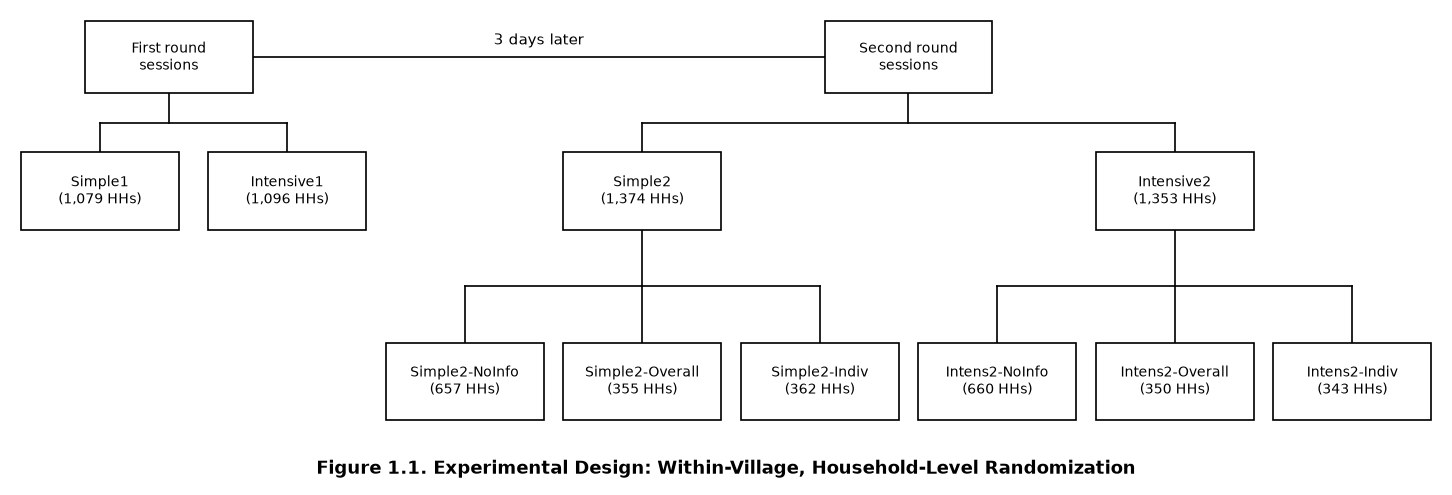

In [2]:
fig = plot_household_design()

There are 4 different randomizations in this experiment, two at household level and two at village level. First, all households are in the sample were randomly assigned to one of the 4 sessions: first round simple (Simple1), first round intensive (Intensive1), second round simple (Simple2), second round intensive (Intensive2). This randomization generates varitions among second round participants 

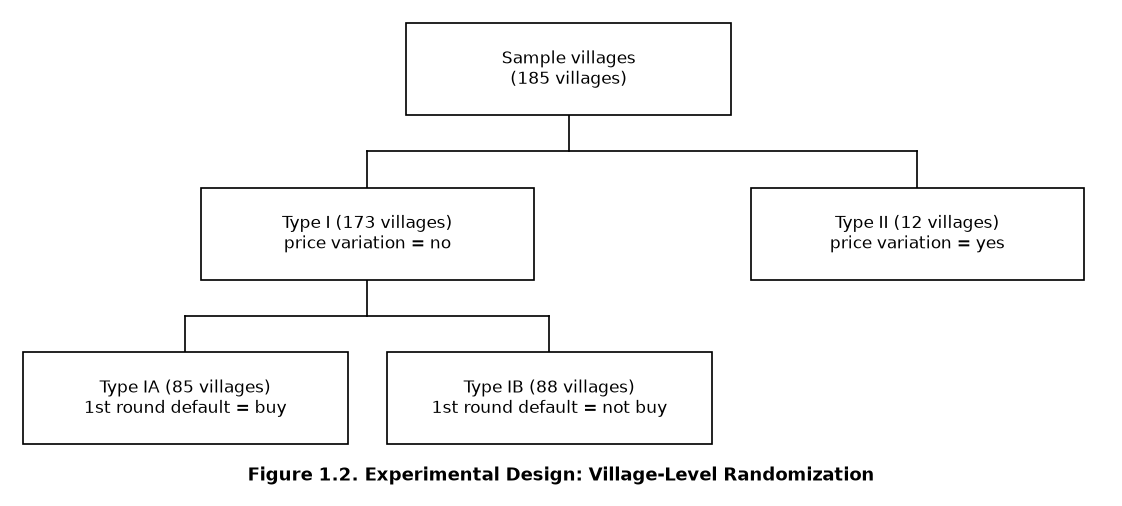

In [3]:
fig = plot_village_design()

**Village-level Randomization:**

First, researchers randomly divided villages into two types. In type 1 villages, all households face the same price of 3.6 RMB per mu, while in type II villages, researchers randomly assigned 1 of 7 different prices ranging from 1.8 to 7.2 RMB per mu to different participants. Within type I villages, they also randomized the default option to buy in first round
sessions. If the default was “buy,” the farmer needed to sign off if he did not want
to purchase the insurance; if the default was “not buy,” the farmer had to sign on
if he decided to buy the insurance. The objective of these different default options was to generate exogenous variations in the first round insurance take-up across villages which could be used in some estimations as instrument variables (IV).

**Social Network Characteristics:**

Researchers also construct three social network structural characteristics as indicators for the importance of a given household in a network:
<ol type="i">
  <li>in-degree, which is the number
of persons that named the household as a friend</li>
  <li>path length, which is the mean
of the shortest paths to this household from any other household</li>
  <li>eigenvector centrality, which measures a household’s importance in the overall flow of information</li>
</ol>

**Household Characteristics ($X_{ij}$):**

To check whether randomizations in Type II villages are valid, they set up a regression model:

$$
X_{ij} = \alpha_0 + \alpha_1 \, \text{Price}_{ij} + \eta_j + \epsilon_{ij}
$$

where:
- $X_{ij}$: a household characteristic (gender, age, and literacy of household head, household size, and area of rice production) for household $i$ in village $j$
- $\text{Price}_{ij}$: the randomly offered insurance price
- $\eta_j$: village fixed effect
- $\epsilon_{ij}$: error term

## 3. Causal Relations

Cai et al. (2015) paper aims to evaluate how social networks affects farmers decision to buy weather insurance.

Researchers create randomization to close backdoor path into treatment so differences in take-up are causal relationships. The only confounding variable is the peer's behavior so Village default (Type IA buy vs Type IB not buy) serves as instrument variable. 

Our fundamental problem of causal analysis is that within one observation, a farmer can not have both control and treatment effect so farmer's true outcome is dependent on the treatment of friends and the social network effect. 

All the numbered equations here are based on paper's numbering

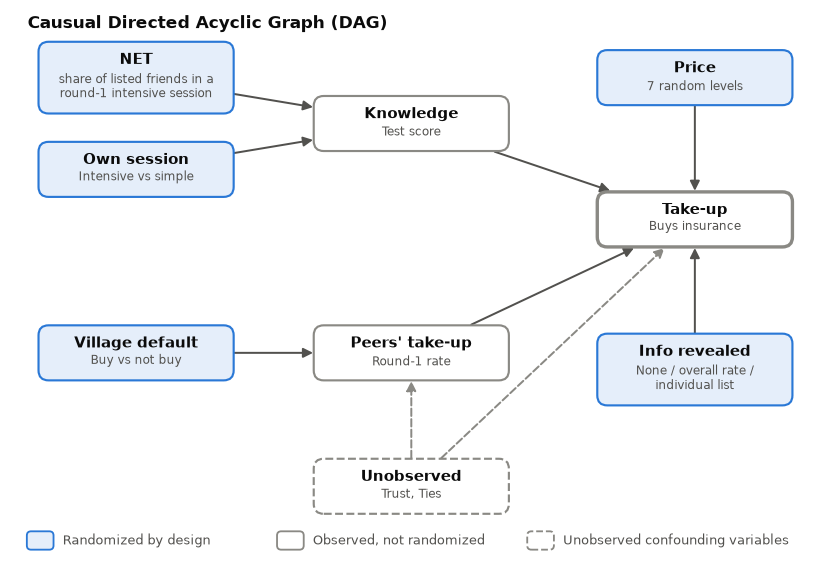

In [4]:
fig = plot_dag()

- Intensive vs Simple session can improve knowledge about the product which eventually leads to insurance take-up and he same goes for related friends being treated
- Village default leads to peers' take-up of the product and then eventually observation take-up.
- Price differences also leads into take-up and translate that into monetary equivalence.
- The unobserved node or the underlying structure of the social network drives both peers and own take-up. This is accounted for with the randomized village default.

## 4. Emperical Strategy

To gather evidence about social network effect on insurance take-up, researchers first focus on the sample of farmers assigned to second round groups who did not receive first round take up information (`Simple2-NoInfo` and `Intensive2-NoInfo`) and set up the regression:
$$\text{Takeup}_{ij} = \tau_0 + \tau_1 \, \text{Network}_{ij} + \tau_2 X_{ij} + \tau_3 \, \text{NetSize}_{ij} + \eta_j + \epsilon_{ij}$$

where:
- $\text{Takeup}_{i}$ is 1 when household i buy the insurance, 0 otherwise 
- $\text{Network}_{ij}$ (NET) is the fraction of named friends who have been invited to first round intensive session
- $X_{ij}$ is the household characteristics introduced in part 2
- $\text{NetSize}_{ij}$ is a set of five dummy variables indicatin the number of listed friends

Researchers then assess the importance of the social network effect by measuring its price equivalence through price randomization in type II villages. The underlying theory is that information may affect both the level and price sensitivity of insurance demand. The intuition is that farmer's limietd understandin of insurance can be modeled by adding an uncertain subjective term to payout scheme of the insurance contract. Demand for insurance thus rely positively on perceived benefit of insurance and negatively on its uncertainty.

The team then formalize the relationship with the following equation:

\begin{aligned}
\text{Takeup}_{ij} &= \gamma_0 + \gamma_1 \text{Price}_{ij} + \gamma_2 \text{Network}_{ij} \\
&\quad + \gamma_3 \, \text{Price}_{ij} \times \text{Network}_{ij} \\
&\quad + \gamma_4 X_{ij} + \gamma_5 \text{NetSize}_{ij} + \eta_j + \epsilon_{ij}
\end{aligned}

where:
- $\text{Price}_{ij}$ is the price randomly assigned to house i in villege j, which takes 1 of 7 different values ranging from 1.8 to 7.2 RMB per mu.
- $\eta_j$ is the fixed effect of village j
- Other variables are defined above

Researchers then estimate the price equivalence $P$ of the social network effect using the formula:
$$P = \frac{\left[\hat{\gamma}_2 + \hat{\gamma}_3 \, mean(\text{Price}) \right] \times 0.2}{\hat{\gamma}_1 + \hat{\gamma}_3 \, mean(\text{Network})}$$

After looking into the price equivalence, the research team look deeper into how do social network operate or what is it that farmers learned from their informed friends that changed their decisions. In general based on literature review, adoption of financial product are based on 3 reasons:
<ol type="i">
  <li> Gain knowledge from their friends about the value of the
product (Conley and Udry 2010; Kremer and Miguel 2007)</li>
  <li> Learn from their friends about product usage (Munshi and Myaux 2006; Oster and Thornton
2012)</li>
  <li>people are influenced by other individuals’ decisions (Bandiera and Rasul 2006; Banerjee 1992; Beshears et al. 2014; Bursztyn et al. 2014)</li>
</ol>

Specifically, in the last case, farmers can be influenced by their friends decisions because of scale effects, desire to imitate, or existence of informal risk-sharing arrangements (Bloch, Genicot, and Ray 2008)

Focusing on the role of friends in diffusing insurance knowledge, researchers test whether farmers have a better understandin when they had more friends invited to a first round intensive sessions by estimating:
$$\text{Knowledge}_{ij} = \lambda_0 + \lambda_1 \text{Network}_{ij} + \lambda_2 \text{Intensive}_{ij} + \lambda_3 X_{ij} + \eta_j + \epsilon_{ij}$$
where:
- $\text{Knowledge}_{ij}$ is the score that a household obtained on a ten-question insurance knowledge test
- $\text{Intensive}_{ij}$ is a dummy variable equal to one if the household was invied to an intensive session in village j.

The next important result come from analyzing whether information about friends' decisions has similar effect on farmers' decisions as information about the overall take-up rate. They achieve that goal by estimate using the sample of second round participants who either did not receive any take-up information or received from the research team the first round decision list (`Simple2-NoInfo`, `Intens2-NoInfo`, `Simple2-Indiv` and `Intens2-Indiv` explained above):

\begin{aligned}
\text{Takeup}_{ij} &= \delta_0 + \delta_1 \text{TakeupRate}_j + \delta_2 \text{TakeupRateNetwork}_{ij} + \delta_3 \text{Info}_{ij} \\
&\quad + \delta_4 \, \text{TakeupRate}_j \times \text{Info}_{ij} + \delta_5 \, \text{TakeupRateNetwork}_{ij} \times \text{Info}_{ij} + \epsilon_{ij}
\end{aligned}

where:
- $\text{TakeupRate}$ is the share of round-1 participants in village j who bought.
- $\text{TakeupRateNetwork}$ is the same share among the household's own friends who attended round 1.
- $\text{Info}$ is 1 if the experimenters told the farmer the round-1 results, and 0 if not.

We use Two-Stages Least Squares (2SLS) here since our peer's take-up (`TakeupRate` and `TakeupRateNetwork`) are endogenous. This is a problems since there are potentially an unobserved shared factor like trust in the insurer agents affect both farmers and their friends. An OLS regression would therefore be biased. Additionally, compared to tfirst 3 equations, we used `TakeupRate` as one of the regressors here which are partly chosen by our experiment design choice. Thus, village default (buy vs. not buy) randomization are introduced to supply exogenous variations and negate the bias. 

## 5. Replication of Cai et al. (2015)

### 5.1 Data and Descriptive Statistics

The replication package ships four raw Stata files. `auxiliary/data.py` rebuilds in pandas the variables the authors construct in Stata: the friend-network measures and the natural-village first-round take-up rate `pre_takeup_rate`.

In [5]:
full = load_analysis_data()
print(
    f"Survey: {len(full):,} households, {full['address'].nunique()} natural villages, "
    f"{full['village'].nunique()} admin villages"
)

Survey: 4,902 households, 173 natural villages, 47 admin villages


Our main design use the second-roun households who received inforation about first-round take-up (with delay == 1 and info_none == 0): 1,410 households with 166 natural villages and 44 admin villages. Second round households told nothing (info_none == 1) are kept aside as placebo effect

Data Cleaning: We drop households missing any control and cap `ricearea_2010` at its 99th percentile (the maximum is 650 mu against a median of 10).

In [6]:
raw = main_sample(full)
df, cleaning_report = clean(raw)
placebo, _ = clean(placebo_sample(full))
cleaning_report

,missing
age,4
agpop,6
ricearea_2010,9
literacy,21
male,3
risk_averse,0
rows dropped (any missing),32
ricearea_2010 cap (p99),80
rows kept,1378


#### Table 1: Descriptive Statistics

In [7]:
table1_vars = [
    "takeup_survey",
    "pre_takeup_rate",
    "default",
    "intensive",
    "age",
    "agpop",
    "ricearea_2010",
    "literacy",
    "male",
    "risk_averse",
    "disaster_prob",
    "understanding",
]
style_table(summary_table(raw, table1_vars, VARIABLE_LABELS))

,N,Mean,SD,Min,Max,Missing
Insurance take-up,1410,0.464,0.499,0,1,0
1st-round take-up rate (natural village),1410,0.429,0.241,0,1,0
Default = buy,1410,0.484,0.500,0,1,0
Intensive session,1410,0.491,0.500,0,1,0
Age of household head,1406,51.481,12.148,18,86,4
Household size,1404,4.901,2.076,1,19,6
Rice area (mu),1401,13.429,21.876,0.400,650,9
Literate,1389,0.793,0.405,0,1,21
Male household head,1407,0.903,0.297,0,1,3
Risk aversion,1410,0.176,0.306,0,1,0


**Randomization check**

Covariate means by `default` and by `intensive`, with p-vlauesn from regressing $covariate \sim treatment$. We would expect small differences in means and covariate should not correlate with treatment (high p-values)

#### Table 1.1 - 1.3: Randomization Check

In [8]:
balance_vars = [
    "age",
    "agpop",
    "ricearea_capped",
    "literacy",
    "male",
    "risk_averse",
    "disaster_prob",
]
price = load_price_data()

display(style_table(balance_table(df, "default", balance_vars, VARIABLE_LABELS)))
style_table(balance_table(df, "intensive", balance_vars, VARIABLE_LABELS))
price_balance_table(price)

,default = 0,default = 1,Difference,Std. Error,P-Value
Variable,,,,,
Age of household head,51.874,50.913,-0.961,0.741,0.197
Household size,4.972,4.806,-0.166,0.147,0.259
"Rice area, capped at p99 (mu)",12.763,12.849,0.086,0.971,0.930
Literate,0.784,0.805,0.021,0.025,0.422
Male household head,0.902,0.902,0.000,0.023,0.985
Risk aversion,0.173,0.176,0.002,0.018,0.897
Perceived disaster probability (%),33.092,33.021,-0.071,0.866,0.935


,Slope on price,Std. Error,P-Value
Variable,,,
age,4.040e-01,0.314,0.225
agpop,-1.346e-02,0.048,0.784
earlyarea,-5.445e-04,0.195,0.998
literacy,-6.561e-03,0.013,0.635
male,2.061e-03,0.012,0.867
risk_averse,-3.276e-03,0.011,0.766
intensive,-6.523e-02,0.033,0.071


In [9]:
# Check price randomization
price = load_price_data()
price_balance_table(price)

,Slope on price,Std. Error,P-Value
Variable,,,
age,4.040e-01,0.314,0.225
agpop,-1.346e-02,0.048,0.784
earlyarea,-5.445e-04,0.195,0.998
literacy,-6.561e-03,0.013,0.635
male,2.061e-03,0.012,0.867
risk_averse,-3.276e-03,0.011,0.766
intensive,-6.523e-02,0.033,0.071


Similar to the paper results, all the coefficient estimates are small in magnitude and none is statistically significant so we can be confident that price randomization is valid

### 5.2. Results

Results are reported as one numbered table or figure per claim. P-values are colour-coded: <span style="color:red">red < 0.1% (Highly significant)</span>, <span style="color:darkorange">orange < 1% (Very Significant)</span>, <span style="color:goldenrod">yellow < 5% (Statistically significant)</span>, no colour otherwise or not statistically significant at all.

All four models follow the authors' specifications in `analysis.do`. Each table reports the estimate, standard error clustered by natural village, p-value and N for the regressors of interest. As in the paper, household characteristics $X_{ij}$ (gender, age, literacy of the household head, household size, rice area, and, except in 5.2.4, risk aversion and perceived disaster probability), the number-of-friends dummies and village fixed effects are included but summarised as Yes/No rows, followed by R-squared and adjusted R-squared.

#### 5.2.1 Social network effect on take-up (Eq. 1)

$$\text{Takeup}_{ij} = \tau_0 + \tau_1 \text{Network}_{ij} + \tau_2 X_{ij} + \tau_3 \text{NetSize}_{ij} + \eta_j + \epsilon_{ij}$$

On `Simple2-NoInfo` and `Intensive2-NoInfo` households, with the household's own `Intensive` dummy added as in the paper (Table 2, column 2).

In [10]:
fit_eq1 = eq1_network_model(full)
style_table(regression_table(fit_eq1))

,Estimate,Std. Error,P-Value,N
Network (share of friends in 1st-round intensive),0.291,0.082,0.001,1255
Intensive session,0.030,0.033,0.370,1255
Household characteristics,Yes,,,
Number-of-friends dummies,Yes,,,
Village fixed effects,Yes,,,
R-squared,0.119,,,
Adjusted R-squared,0.079,,,


*Interpretation: TODO*

#### 5.2.2 Price equivalence of the network effect (Eq. 2)

Take-up on Price, Network and Price × Network in type II (price-randomized) villages, with natural-village fixed effects because price is randomized within the natural village (paper Table 4, column 2).

In [11]:
fit_eq2 = eq2_price_model(price)
style_table(regression_table(fit_eq2))

,Estimate,Std. Error,P-Value,N
Price (RMB/mu),-0.151,0.019,0.000,433
Network (share of friends in 1st-round intensive),-0.178,0.237,0.469,433
Price x Network,0.125,0.049,0.027,433
Intensive session,0.037,0.028,0.221,433
Household characteristics,Yes,,,
Number-of-friends dummies,Yes,,,
Village fixed effects,Yes,,,
R-squared,0.270,,,
Adjusted R-squared,0.222,,,


*Price equivalence $P$ and interpretation: TODO*

#### 5.2.3 Knowledge channel (Eq. 3)

$\text{Knowledge}_{ij} = \lambda_0 + \lambda_1 \text{Network}_{ij} + \lambda_2 \text{Intensive}_{ij} + \lambda_3 X_{ij} + \eta_j + \epsilon_{ij}$ (paper Table 5, column 3).

In [12]:
fit_eq3 = eq3_knowledge_model(full)
style_table(regression_table(fit_eq3))

,Estimate,Std. Error,P-Value,N
Network (share of friends in 1st-round intensive),0.290,0.049,0.000,1255
Intensive session,0.073,0.017,0.000,1255
Household characteristics,Yes,,,
Number-of-friends dummies,No,,,
Village fixed effects,Yes,,,
R-squared,0.130,,,
Adjusted R-squared,0.093,,,


*Interpretation: TODO*

#### 5.2.4 Friends' decisions vs. overall take-up rate (Eq. 4, 2SLS)

\begin{aligned}
\text{Takeup}_{ij} &= \delta_0 + \delta_1 \text{TakeupRate}_j + \delta_2 \text{TakeupRateNetwork}_{ij} + \delta_3 \text{Info}_{ij} \\
&\quad + \delta_4 \, \text{TakeupRate}_j \times \text{Info}_{ij} + \delta_5 \, \text{TakeupRateNetwork}_{ij} \times \text{Info}_{ij} + \epsilon_{ij}
\end{aligned}

In Paper Table 7, column 2. Sample: `Simple2-NoInfo`, `Intens2-NoInfo`, `Simple2-Indiv`, `Intens2-Indiv`.

In [13]:
fit_eq4 = eq4_info_iv_model(full)
style_table(regression_table(fit_eq4))

,Estimate,Std. Error,P-Value,N
No info (told nothing),0.274,0.329,0.407,1500
Intensive session,0.029,0.030,0.332,1500
TakeupRateNetwork (friends),0.556,0.259,0.033,1500
TakeupRate (village),0.881,0.726,0.226,1500
TakeupRate x No info,-0.736,1.018,0.471,1500
TakeupRateNetwork x No info,-0.014,1.199,0.991,1500
Household characteristics,Yes,,,
Number-of-friends dummies,No,,,
Village fixed effects,Yes,,,
R-squared,,,,


*Interpretation: TODO*

## References (Chicago author-date style):

**Bloch, Francis, Garance Genicot, and Debraj Ray.** 2008. “Informal insurance in social networks.” Journal of Economic Theory 143 (1): 36–58.

**Conley, Timothy G., and Christopher R. Udry. 2010.** “Learning about a New Technology: Pineapple in
Ghana.” American Economic Review 100 (1): 35–69.

**Kremer, Michael, and Edward Miguel.** 2007. “The Illusion of Sustainability.” Quarterly Journal of Economics 122 (3): 1007–65.

**Munshi, Kaivan, and Jacques Myaux.** 2006. “Social norms and the fertility transition.” Journal of Development Economics 80 (1): 1–38.

**Oster, Emily, and Rebecca Thornton.** 2012. “Determinants of Technology Adoption: Private Value
and Peer Effects in Menstrual Cup Take-up.” Journal of the European Economic Association 10
(6): 1263–93.

**Bandiera, Oriana, and Imran Rasul. 2006.** “Social Networks and Technology Adoption in Northern
Mozambique.” Economic Journal 116 (514): 869–902.

**Banerjee, Abhijit V.** 1992. “A Simple Model of Herd Behavior.” Quarterly Journal of Economics 107(3): 797–817.

**Beshears, John, James J. Choi, David Laibson, Brigitte C. Madrian, and Katherine L. Milkman.** Forthcoming. “The Effect of Providing Peer Information on Retirement Savings Decisions.” Journal of Finance. 

**Bursztyn, Leonardo, Florian Ederer, Bruno Ferman, and Noam Yuchtman.** 2014. “Understanding Peer
Effects in Financial Decisions: Evidence from a Field Experiment.” Econometrica 82 (4): 1273–
1301.

**Cai, Jing, Alain De Janvry, and Elisabeth Sadoulet.** 2015. “Social Networks and the Decision to
Insure: Dataset.” American Economic Journal: Applied Economics. http://dx.doi.org/10.1257/app.20130442.